# Tuned In — Pilot Study v2 app-improvement analysis

This report reviews the 20-record silent calibration, task performance, adaptive playback, and questionnaire handover for PIL004–PIL006.

## Run and interpretation

Run cells from top to bottom in a Python 3 Jupyter kernel with `pandas`, `numpy`, `matplotlib`, and `openpyxl` installed. Both pilot notebooks use the same stages in `pilot_analysis.py`. Source files are read-only. No current app configuration is substituted for historical settings, and no app code is changed.

The inputs are copied alongside the previous feedback archives under `feedback-files/results/`. Paths are resolved relative to the repository, so the notebook works from either the repository root or its analysis folder. Source hashes are printed below.

- Experimental form blocks **1–3** map to exported task blocks **2–4** (`form block = task block - 1`); exported blocks 0 and 1 are practice and calibration.
- The join reports missing or unmatched keys and stops on duplicate keys.
- Missing questionnaire values are not imputed. Flagged timing records remain visible; a separate sensitivity summary is shown.
- With three participants, report individual patterns and counts. No significance tests, causal rankings, or threshold tuning to maximize a PFS score are performed.

The questionnaire workbook contains both pilots. The input cell identifies the earlier participants so their rows can be shown and excluded before scoring. The ZIP also includes standalone JSON copies, which are checked against the participant bundles.

In [2]:
from pathlib import Path
import sys

from IPython.display import display

results_folder = Path("feedback-files/results")
root = next((path for path in (Path.cwd(), *Path.cwd().parents)
             if (path / results_folder).is_dir()), None)
if root is None:
    raise FileNotFoundError("Start the notebook from within the TunedIn-Web repository.")
sys.path.insert(0, str(root / "feedback-files/analysis"))

import pilot_analysis as pilot

pilot.configure_display()
export_zip = root / results_folder / "pilot-study-v2.zip"
questionnaire = root / results_folder / "pilot-study-v2-pfs.xlsx"
questionnaire_options = {
    "sheet_name": "Form Responses 1",
    "prior_cohort": ("PIL001", "PIL002", "PIL003"),
}
display(pilot.input_provenance(export_zip, questionnaire))

,input,bytes,sha256
0,pilot-study-v2.zip,339536,8e01e901ae3589be3e959f08481489fcac861e772fdd77...
1,pilot-study-v2-pfs.xlsx,7887,37304754a3fb8075798ed1c6f9b5caff19883bf1a2223e...


## 1. Load every participant bundle without double-counting

The recursive loader accepts a ZIP of participant ZIPs or export folders within the archive and ignores macOS metadata. Each `session.json` is matched to CSV/JSONL files in its own folder. Duplicate session IDs cause an explicit error. Full raw events from `session.json` are retained for audit; historical exports need not have the newer event IDs or attempt IDs.

In [3]:
bundles, blocks, records, decisions, transitions, completed, experimental = (
    pilot.load_exports(export_zip, display)
)

Verified 3 standalone session copies against the participant bundles.
3 sessions; 15 block rows; 404 record rows; 27 decisions; 7 transitions


,session_id,participant_id,mode,build,order,baseline_mode,baseline_target,early_end
0,291277a9-c3c6-46c4-87a2-5f5dc902d6d6,PIL004,Pilot,pilot-2.0.0,No music → Static music → Adaptive music,records,20,None
1,1a520092-da15-40c7-947f-997c958d9d16,PIL005,Pilot,pilot-2.0.0,Static music → Adaptive music → No music,records,20,None
2,5207a354-9fb2-4e54-aaf9-2f5d464ecb36,PIL006,Pilot,pilot-2.0.0,Adaptive music → No music → Static music,records,20,None


,participant_id,block,form_block,condition,duration_seconds,validated_records,validated_records_per_minute,first_pass_error_rate
2,PIL004,2,1,No music,300.000,49,9.800,0.082
3,PIL004,3,2,Static music,300.000,50,10.000,0.020
4,PIL004,4,3,Adaptive music,300.000,51,10.200,0.000
7,PIL005,2,1,Static music,300.000,25,5.000,0.160
8,PIL005,3,2,Adaptive music,300.000,24,4.800,0.042
9,PIL005,4,3,No music,300.000,25,5.000,0.160
12,PIL006,2,1,Adaptive music,300.000,32,6.400,0.094
13,PIL006,3,2,No music,300.000,31,6.200,0.032
14,PIL006,4,3,Static music,300.000,30,6.000,0.067


## 2. Audit raw events and independently reconcile exported measures

This audit checks duplicate sequences, event order, submission/validation pairing, JSONL agreement, and record/block calculations. One presented but unsubmitted record at a timed boundary is expected and is counted separately; it is not automatically a lost event.

Block timing metrics use first-submitted records; TTSV uses successfully validated records. First-pass error rate uses first-submitted records with validation outcomes. Correction cycles count submissions after the first attempt, matching the app's existing definitions.

In [4]:
raw_records = pilot.audit_exports(bundles, records, completed, display)

Raw-event audit


,participant_id,events,duplicate_sequences,sequence_order_errors,duplicate_presentations,duplicate_first_keys,submitted_missing_first_key,unpaired_records,negative_timing_records,no_presentation_records,jsonl_agrees,presented_not_submitted,submitted_not_validated
0,PIL004,729,0,0,0,0,0,0,0,0,True,4,0
1,PIL005,427,0,0,0,0,0,0,2,0,True,3,1
2,PIL006,491,0,0,0,0,0,0,0,0,True,4,0


Records with negative timing values


,participant_id,block,record_id,il_ms,fped_ms,ttsv_ms
186,PIL005,1,S1-R2,"3,342.100","-3,288.600","17,966.400"
271,PIL005,4,S4-R16,"1,997.000","-1,946.600","14,460.800"


Record-level export reconciliation


,field,mismatched_rows
0,presented_ms,0
1,first_key_ms,0
2,first_submission_ms,0
3,validated_ms,0
4,il_ms,0
5,fped_ms,0
6,ttsv_ms,0
7,submission_count,0
8,first_pass_rejected,0


Unmatched record keys: 0
Block measure mismatches: 0


## 3. Task friction and correction burden

Look for records/fields that require corrections and unusually long initiation/entry times. These are prompts for usability follow-up, not evidence that a particular music condition caused difficulty. The three counterbalanced orders provide coverage, but three sessions cannot isolate condition, practice, fatigue, or individual differences.

,participant_id,form_block,condition,validated_records_per_minute,first_pass_error_rate,correction_cycles,corrections_per_validated,median_il_s,median_fped_s
2,PIL004,1,No music,9.800,0.082,4,0.082,0.675,4.770
3,PIL004,2,Static music,10.000,0.020,1,0.020,0.647,4.887
4,PIL004,3,Adaptive music,10.200,0.000,0,0.000,0.649,4.961
7,PIL005,1,Static music,5.000,0.160,4,0.160,1.113,9.886
8,PIL005,2,Adaptive music,4.800,0.042,1,0.042,1.146,10.404
9,PIL005,3,No music,5.000,0.160,4,0.160,1.044,9.480
12,PIL006,1,Adaptive music,6.400,0.094,3,0.094,1.055,7.496
13,PIL006,2,No music,6.200,0.032,1,0.032,1.262,7.932
14,PIL006,3,Static music,6.000,0.067,2,0.067,1.234,7.762


Experimental-block incorrect fields across all rejected submissions (a submission can have several incorrect fields)


classification,case_only,other_mismatch
field,,
batchCode,0,5
quantity,0,7
recordCode,4,7


Case-only checks use a later accepted submission of the SAME record as the answer key; no historical record generator is assumed.


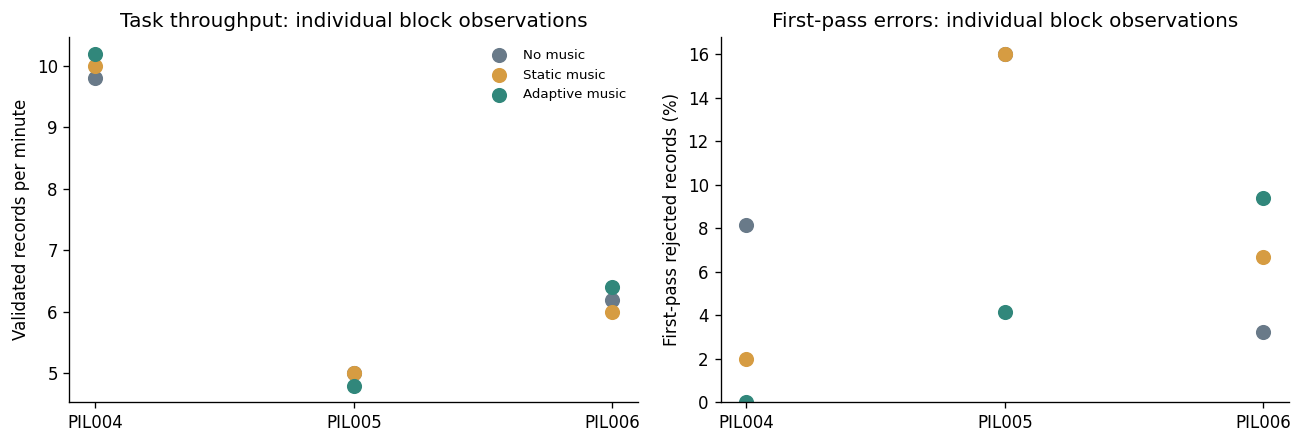

In [5]:
performance = pilot.analyze_task(bundles, experimental, display)

### Experimental-block record counts and historical time-to-15 comparison

“Completed” means successfully validated: correcting the same record still completes only one distinct record. Counts below exclude practice and silent calibration. Each experimental block lasted 300 seconds in these exports.

The tables report completed records by condition and block position, plus **directly observed** counts in each block's first 120 seconds and the elapsed time at which the 15th distinct record was validated. Timing is relative to the first record presentation in that block; it is not the form submission time or the participant's session clock origin.

The shared report retains the time-to-15 measure for continuity with v1. Each v2 silent calibration had a 20-record target.

In [6]:
main_record_counts = pilot.analyze_record_counts(experimental, completed, raw_records, records, display)

Completed experimental blocks


,participant_id,form_block,exported_block,condition,duration_seconds,records_presented,records_submitted,records_completed,completed_per_minute,completed_in_first_120s,seconds_to_15_completed,presented_not_completed
0,PIL004,1,2,No music,300.000,50,49,49,9.800,20,85.656,1
1,PIL004,2,3,Static music,300.000,51,50,50,10.000,21,86.691,1
2,PIL004,3,4,Adaptive music,300.000,52,51,51,10.200,20,90.308,1
3,PIL005,1,2,Static music,300.000,26,25,25,5.000,10,169.587,1
4,PIL005,2,3,Adaptive music,300.000,25,24,24,4.800,9,182.036,1
5,PIL005,3,4,No music,300.000,26,25,25,5.000,9,185.606,1
6,PIL006,1,2,Adaptive music,300.000,33,32,32,6.400,13,136.180,1
7,PIL006,2,3,No music,300.000,32,31,31,6.200,12,137.885,1
8,PIL006,3,4,Static music,300.000,31,30,30,6.000,12,147.345,1


Completed records by condition


condition,No music,Static music,Adaptive music,total_main_records
participant_id,,,,
PIL004,49,50,51,150
PIL005,25,25,24,74
PIL006,31,30,32,93


Completed records by experimental position; condition order differs across participants


form_block,Block 1,Block 2,Block 3
participant_id,,,
PIL004,49,50,51
PIL005,25,24,25
PIL006,32,31,30


Directly observed early-main-block completion and any 120-second timed baselines


,main_first_120s_min,main_first_120s_max,main_time_to_15_min_s,main_time_to_15_max_s
participant_id,,,,
PIL004,20,21,85.656,90.308
PIL005,9,10,169.587,185.606
PIL006,12,13,136.180,147.345


Main-block totals and time-to-15 range


,experimental_blocks,total_records_completed,completed_per_block_min,completed_per_block_max,time_to_15_min_s,time_to_15_median_s,time_to_15_max_s
0,9,317,24,51,85.656,137.885,185.606


### Directly observed time to 20 completed records

The following calculation measures the interval from each main block's first record presentation to acceptance of its 20th distinct record, including correction time. It uses the record timings loaded from the participant exports. Practice and silent baseline are excluded.

In [7]:
pilot.report_time_to_20(main_record_counts, display)

,participant_id,form_block,condition,seconds_to_20_completed
0,PIL004,1,No music,119.865
1,PIL004,2,Static music,112.940
2,PIL004,3,Adaptive music,116.736
3,PIL005,1,Static music,231.771
4,PIL005,2,Adaptive music,239.741
5,PIL005,3,No music,237.585
6,PIL006,1,Adaptive music,180.694
7,PIL006,2,No music,186.827
8,PIL006,3,Static music,194.549


9 of 9 experimental blocks reached 20 accepted records.


,median,min,max
participant_id,,,
PIL004,116.736,112.940,119.865
PIL005,237.585,231.771,239.741
PIL006,186.827,180.694,194.549


Median 186.827 s, mean 180.079 s, range 112.940–239.741 s.


## 4. Silent baseline calibration: record counts and results

This section describes **exported block 1**, the silent calibration targeting 20 accepted records. It is separate from practice (block 0) and the experimental No Music condition (block 2, 3, or 4 depending on condition order).

- **Presented:** records shown, including a final unfinished record when time expires.
- **First submitted:** distinct records with at least one submission, not the number of submission attempts.
- **Validated:** records eventually accepted, including corrected records.
- **First-pass correct / rejected:** whether the first submission of a record was accepted or rejected. A later correction does not turn a first-pass rejection into a first-pass success.
- **Correction cycles:** additional submission attempts after the first.
- **Reference IL / FPED:** participant-specific median initiation latency and first-pass entry duration used as adaptive timing references. Their sample sizes are shown explicitly.

Totals below pool counts only. They do not replace individual calibration references with a pooled timing median, and do not establish a required minimum baseline sample size.

In [8]:
baseline_counts = pilot.analyze_calibration(completed, raw_records, display)

Baseline record counts (one row per participant)


,participant_id,baseline_mode,baseline_target_records,duration_seconds,records_presented,first_submitted_records,validated_records,presented_not_submitted,submitted_not_validated,first_pass_correct,first_pass_rejected_records,correction_cycles,il_reference_records,fped_reference_records
0,PIL004,records,20,116.776,20,20,20,0,0,20,0,0,20,20
1,PIL005,records,20,268.468,20,20,20,0,0,16,4,5,20,20
2,PIL006,records,20,192.974,20,20,20,0,0,20,0,0,20,20


Baseline performance and participant-specific timing references


,participant_id,validated_records_per_minute,first_pass_error_percent,first_pass_accuracy_percent,reference_il_seconds,reference_fped_seconds,median_validation_time_seconds,correction_cycles_per_validated_record
1,PIL004,10.276,0.000,100.000,0.724,5.040,5.761,0.000
6,PIL005,4.470,20.000,80.000,1.304,9.934,12.248,0.250
11,PIL006,6.218,0.000,100.000,1.211,8.243,9.859,0.000


Combined baseline counts and rates; pooled rates are ratios of totals, not averages of participant percentages


,participants,total_baseline_minutes,records_presented,first_submitted_records,validated_records,presented_not_submitted,submitted_not_validated,first_pass_correct,first_pass_rejected_records,correction_cycles,pooled_validated_records_per_minute,pooled_first_pass_accuracy_percent
0,3,9.637,60,60,60,0,0,56,4,5,6.226,93.333


### Block-boundary and adaptive scheduling checks

Configured duration and wall-clock duration are separate checks. Decision timing is measured relative to the first presentation in the relevant block. The baseline results above remain distinct from the experimental-block scheduling checks below.

In [9]:
block_meta, decision_audit = pilot.audit_scheduling(bundles, raw_records, decisions, experimental, display)

Wall-clock duration minus saved block duration (seconds)


,min,max
participant_id,,
PIL004,0.035,0.101
PIL005,0.028,0.086
PIL006,0.015,0.076


,total_evaluations,in_block_evaluations,terminal_evaluations,waiting_evaluations,first_evaluation_s,last_evaluation_s
participant_id,,,,,,
PIL004,9,8,1,0,60.004,300.007
PIL005,9,8,1,0,60.009,300.017
PIL006,9,8,1,0,60.001,300.003


,participant_id,elapsed_s,record_count,previous_state,selected_state,reason
8,PIL004,300.007,11,baseline,baseline,Neither reduced nor elevated trigger condition...
17,PIL005,300.017,4,elevated,baseline,Neither reduced nor elevated trigger condition...
26,PIL006,300.003,6,baseline,reduced,Recent performance met a reduced-state trigger.


## 5. Adaptive decisions and crossfade verification

A retained state is not a transition. Examine actual track-ID changes and their matching browser transition outcomes. Report final-boundary evaluations separately. Do not relax thresholds just because one participant never reaches Elevated: state labels are music-selection categories, not measured psychological states.

selected_state,baseline,reduced,elevated,silent
participant_id,,,,
PIL004,7,0,1,0
PIL005,5,2,1,0
PIL006,6,2,0,0


,transitions,successful,minimum_ms,maximum_ms,mean_deviation_ms
participant_id,,,,,
PIL004,2,2,"5,029.300","5,031.000",30.150
PIL005,3,3,"5,022.200","5,025.100",23.333
PIL006,2,2,"5,023.100","5,035.600",29.350


Track-changing decisions without a transition: 2


,participant_id,block,id,elapsed_s,at_or_after_end
0,PIL005,3,decision-9,300.017,True
1,PIL006,2,decision-9,300.003,True


Transition rows without a matching track-changing decision: 0
Duplicate decision IDs within sessions: 0


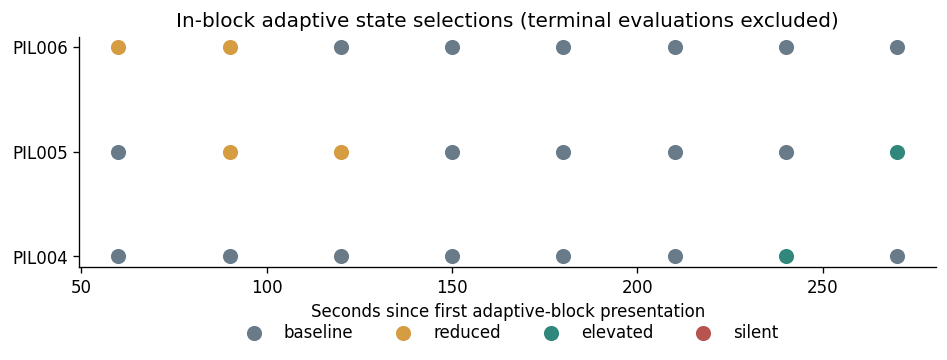

Successful timing logs confirm reported playback completion, not perceived smoothness or headphone comfort; ask participants about those separately.


In [10]:
pilot.audit_playback(bundles, decision_audit, transitions, display)

## 6. Link and score the PFS responses descriptively

The supplied thesis, Appendix E.1, defines nine positively worded 1–7 items: absorption (items 1–3), effortless control (4–6), and intrinsic reward (7–9). Each dimension is the mean of its three items; the overall item mean is retained for completeness. No missing-item imputation or reverse scoring is applied. This notebook does not test flow efficacy or treat the PFS as a dedicated usability scale.

Items are selected by explicit column wording, not by assuming all numeric columns are questionnaire items. Block mapping is checked against each session's assigned condition order, rather than using a fixed condition-to-block mapping.

In [12]:
%pip install openpyxl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [openpyxl]

[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [13]:
pfs, joined = pilot.score_questionnaire(
    questionnaire, experimental, performance, display, **questionnaire_options
)

Earlier pilot questionnaire rows in the supplied workbook


,form_row,participant_id,form_block
0,2,PIL001,1
1,3,PIL001,2
2,4,PIL001,3
3,5,PIL003,1
4,6,PIL003,2
5,7,PIL003,3
6,8,PIL002,1
7,9,PIL002,2
8,10,PIL002,3


In-scope questionnaire rows: 9
Missing form responses: 0 Unmatched form responses: 0
Invalid/missing item rows: 0


,participant_id,form_block,condition,absorption,effortless_control,intrinsic_reward,overall_item_mean
0,PIL004,1,No music,5.667,4.333,3.667,4.556
1,PIL004,2,Static music,5.333,6.333,3.333,5.000
2,PIL004,3,Adaptive music,5.333,6.333,3.667,5.111
3,PIL005,1,Static music,4.667,7.000,6.000,5.889
4,PIL005,2,Adaptive music,4.000,3.333,3.667,3.667
5,PIL005,3,No music,6.000,4.667,4.333,5.000
6,PIL006,1,Adaptive music,4.667,5.333,4.667,4.889
7,PIL006,2,No music,5.333,5.000,3.667,4.667
8,PIL006,3,Static music,5.333,5.000,5.333,5.222


## 7. Questionnaire timing and handover audit

Form timestamps are interpreted as **Asia/Manila local time** (the study location); exported block timestamps are UTC. Confirm that this was the Google Form's configured time zone before treating the timing flags as final.

Check whether each form submission falls between the relevant block's end and the next experimental block's start. Submission time is not necessarily answer time: researcher transcription, offline collection, or delayed entry can explain a flag. Preserve flagged responses and confirm the collection method rather than silently excluding them.

In [14]:
joined = pilot.audit_questionnaire_timing(joined, block_meta, display)

The <=10-second clustering flag is a workflow diagnostic, not a validated response-exclusion rule.


,participant_id,form_block,condition,form_time,minutes_after_block_end,seconds_since_previous_form,after_next_block_start,clustered_submission,timing_review
0,PIL004,1,No music,2026-11-04 12:09:29.956000+08:00,1.581,NaN,False,False,False
1,PIL004,2,Static music,2026-11-04 12:16:47.813000+08:00,1.021,437.857,False,False,False
2,PIL004,3,Adaptive music,2026-11-04 12:23:08.383000+08:00,0.660,380.570,False,False,False
3,PIL005,1,Static music,2026-11-04 13:56:29.979000+08:00,2.157,NaN,False,False,False
4,PIL005,2,Adaptive music,2026-11-04 14:02:27.245000+08:00,0.721,357.266,False,False,False
5,PIL005,3,No music,2026-11-04 14:08:20.509000+08:00,0.623,353.264,False,False,False
6,PIL006,1,Adaptive music,2026-11-04 15:41:52.440000+08:00,0.933,NaN,False,False,False
7,PIL006,2,No music,2026-11-04 15:48:14.872000+08:00,0.690,382.432,False,False,False
8,PIL006,3,Static music,2026-11-04 15:54:14.548000+08:00,0.564,359.676,False,False,False


Flagged participants: None


## 8. PFS item patterns as follow-up usability questions

Low reward or ease ratings can motivate questions about repetition, task purpose, fatigue, or distraction; they do not identify which app feature caused a rating. Retain individual responses and questionnaire timing flags rather than presenting a condition winner. The sensitivity table below merely shows the effect of setting timing-review rows aside pending clarification.

,item,n_valid,mean,median,responses_1_to_3
0,I was absorbed in the task,9,5.889,6.000,0
1,I was highly focused on the task,9,5.222,5.000,0
2,All my attention was on the task,9,4.333,4.000,2
3,I felt like I could easily control what I was ...,9,5.333,5.000,1
4,My actions flowed effortlessly,9,5.222,5.000,0
5,There was a sense of fluidity to my actions,9,5.222,5.000,2
6,I found the experience rewarding,9,4.667,4.000,3
7,The experience felt satisfying,9,4.667,5.000,1
8,I would like the feeling of that experience again,9,3.444,3.000,5


,scope,dimension,n_forms,n_participants,mean,median
0,All linked responses,absorption,9,3,5.148,5.333
1,All linked responses,effortless_control,9,3,5.259,5.000
2,All linked responses,intrinsic_reward,9,3,4.259,3.667
3,Timing-review rows set aside (sensitivity only),absorption,9,3,5.148,5.333
4,Timing-review rows set aside (sensitivity only),effortless_control,9,3,5.259,5.000
5,Timing-review rows set aside (sensitivity only),intrinsic_reward,9,3,4.259,3.667


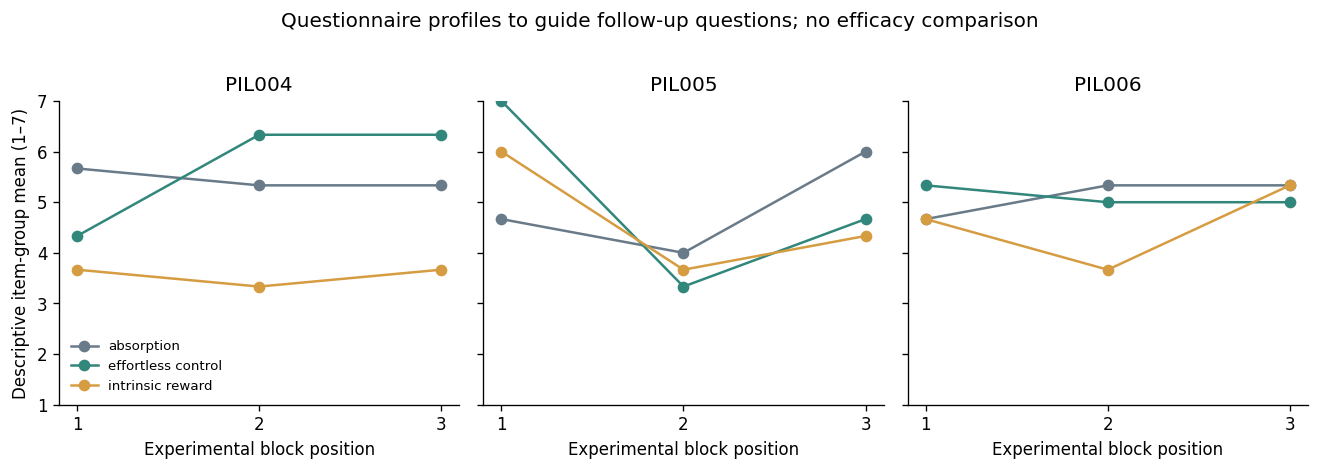

In [15]:
pilot.analyze_questionnaire(pfs, joined, display)

## Pilot v2 findings

- **Calibration.** All three participants reached the 20-record target. The saved durations were 116.776 s for PIL004, 268.468 s for PIL005, and 192.974 s for PIL006. PIL005 had four first-pass rejections and five correction cycles during calibration. Each participant had 20 available IL and FPED observations.
- **Timing audit.** The raw events and CSVs reconciled, but two PIL005 records had negative first-pass entry durations. One was in calibration (S1-R2, −3,288.600 ms) and one was in a main block (S4-R16, −1,946.600 ms). Review the event capture for those records before interpreting timing-reference quality. The reported medians use the archived data as captured.
- **Task performance.** Participants completed 317 records across nine experimental blocks. All nine blocks reached 20 accepted records. The median elapsed time to that point was 186.827 s.
- **Adaptive playback.** The exports contained 27 evaluations, 24 strictly within their blocks. All seven logged transitions reported playback success. Two track-changing decisions had no transition log and both occurred after the nominal 300-second boundary.
- **Questionnaire.** All nine v2 responses linked to completed experimental blocks and had valid item values. The timing checks raised no flags under the Asia/Manila assumption.

These results describe three pilot sessions. The calibration counts confirm that the target was reached in these sessions. Reference stability and the effect of music on flow require separate evidence.
